<center>
    <img src='images/logo.png' width='400px'>
    <h1>MÔN HỌC: THỊ GIÁC MÁY TÍNH (7080518)</h1>
<h2> Chương 2: XỬ LÝ VÀ NÂNG CAO CHẤT LƯỢNG ẢNH - Phần 3</h2>
</center>

---

Xử lý ảnh (Image processing): là quá trình tạo ra ảnh mới từ ảnh có sẵn, VD: tăng độ sáng, cắt ảnh, khử nhiễu,… không tập trung vào việc hiểu nội dung của bức ảnh.

**Nội dung bài học - phần 3:**

**II. Cải thiện chất lượng ảnh:**

1. Làm mờ - mịn  ảnh
    * Làm mờ trung bình
    * Làm mờ trung vị
    * Làm mờ Gaussian
2.  Nhiễu và khử nhiễu trong ảnh
3. Giới thiệu Nhân tích chập
4. Nhân tích chập 2D trong OpenCV

---
*Copyright @dangvannam.FIT.HUMG*
1. Mã sinh viên:2221050292
2. Họ và tên : Phạm Đức Tiến
3. Lớp DCCTCT67-09B
4. Nhóm:200

In [43]:
#Khai báo sử dụng thư viện:
import numpy as np
import matplotlib.pyplot as plt
import cv2
print('Version OpenCV:', cv2.__version__)

Version OpenCV: 4.13.0


### 1. Làm mờ - mịn ảnh với bộ lọc (Blurring images)
---
* Làm mịn ảnh hay còn gọi là làm mờ là một thao tác xử lý đơn giản và được sử dụng thường xuyên trong xử lý ảnh. Có rất nhiều lý do để làm mịn ảnh, Một trong số lý do đó là để giảm nhiễu.
* Để thực hiện thao tác làm mịn ảnh sử dụng một cửa sổ trượt kích thước k x k (kernel). Kích thước kernel càng lớn thì ảnh càng mịn. Giá trị điểm ảnh ở giữa được tính bằng hàm f của toàn bộ điểm ảnh tại vị trí cửa sổ trượt quét qua.

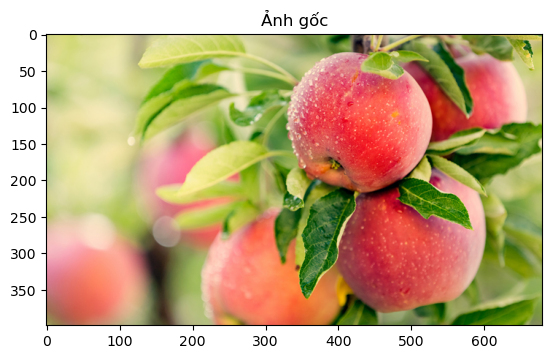

In [44]:
#Đọc ảnh màu: apples.jpg
img = cv2.imread('images/Apples.jpg', cv2.IMREAD_COLOR_RGB)
#hiển thị ảnh
plt.imshow(img)
plt.title('Ảnh gốc')
plt.show()

In [45]:
#Lấy kích thước ảnh ban đầu:
print('Kich thuoc anh goc:', img.shape[0], 'x', img.shape[1])

Kich thuoc anh goc: 399 x 680


**1. phương thức lọc trung bình cv2.blur():**

Phương thức này sử dụng cách thức đơn giản nhất. Mỗi pixel điểm ảnh đầu là là trung bình cộng của các pixel lân cận.

**cv2.blur(src, ksize, borderType)**

Ý nghĩa các tham số:

1. src: ảnh gốc cần thay đổi kích thước.
2. ksize =  (width, height): Kích thước mặt nạ lọc
3. borderType: phương pháp xử lý biên
    * cv2.BORDER_CONSTANT (zero padding)
    * cv2.BORDER_REPLICATE (sao chép)
    * cv2.BORDER_REFLECT  ~ cv2.BORDER_DEFAULT (phản chiếu – mặc định)

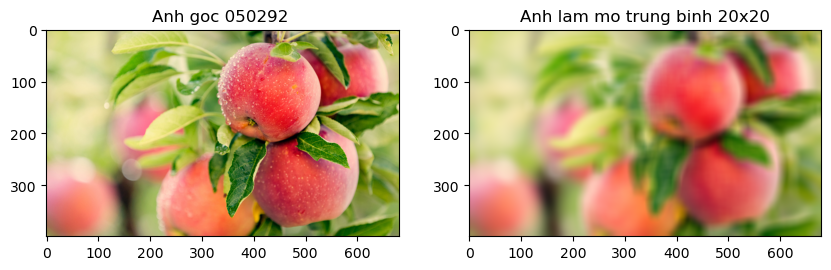

In [46]:
#Sử dụng bộ lọc trung bình trên ảnh:
img_blur = cv2.blur(img, (20,20), cv2.BORDER_CONSTANT)
#Hien thi ket qua:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Anh goc 050292 ')

plt.subplot(1,2,2)
plt.imshow(img_blur)
plt.title('Anh lam mo trung binh 20x20')
plt.show()

In [47]:
#Giá trị điểm ảnh của ảnh gốc:
img[:,:,0]

array([[202, 204, 204, ..., 112, 135,  93],
       [203, 204, 205, ..., 101, 126,  99],
       [202, 204, 206, ..., 123, 148, 120],
       ...,
       [166, 164, 161, ..., 133, 133, 133],
       [171, 168, 166, ..., 135, 134, 134],
       [175, 172, 169, ..., 135, 134, 133]], shape=(399, 680), dtype=uint8)

In [48]:
#Giá trị điểm ảnh của ảnh sau khi sử dụng bộ lọc trung bình:
img_blur[:,:,0]

array([[209, 209, 209, ..., 177, 177, 177],
       [209, 209, 209, ..., 177, 177, 177],
       [209, 209, 209, ..., 176, 176, 176],
       ...,
       [152, 152, 153, ..., 129, 129, 129],
       [152, 152, 152, ..., 129, 129, 129],
       [152, 152, 152, ..., 129, 129, 129]], shape=(399, 680), dtype=uint8)

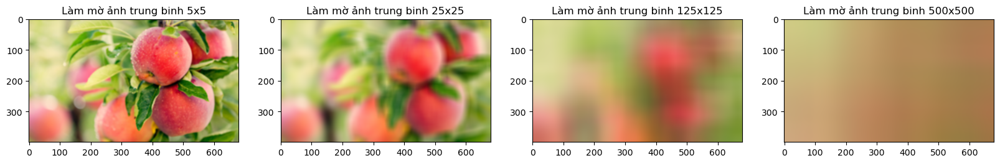

In [49]:
#Làm mờ ảnh theo phương pháp trung bình với kích thước bộ lọc khác nhau:
img_blur_5 = cv2.blur(img,(5,5))
img_blur_25 = cv2.blur(img,(25,25))
img_blur_125 = cv2.blur(img,(125,125))
img_blur_500 = cv2.blur(img,(500,500))

plt.figure(figsize= (20,8))

plt.subplot(1,4,1) 
plt.imshow(img_blur_5)
plt.title("Làm mờ ảnh trung binh 5x5")

plt.subplot(1,4,2) 
plt.imshow(img_blur_25)
plt.title("Làm mờ ảnh trung binh 25x25")

plt.subplot(1,4,3)
plt.imshow(img_blur_125)
plt.title("Làm mờ ảnh trung binh 125x125")

plt.subplot(1,4,4)
plt.imshow(img_blur_500)
plt.title("Làm mờ ảnh trung binh 500x500")
plt.show()

**2. phương thức lọc trung vị cv2.medianBlur():**
Bộ lọc trung vị chạy qua từng phần tử của tín hiệu (trong trường hợp này là hình ảnh) và thay thế mỗi pixel bằng trung vị của các pixel lân cận (nằm trong vùng lân cận hình vuông xung quanh pixel được đánh giá).

**cv2.MedianBlur(src, ksize)**

Ý nghĩa các tham số:

1. src: ảnh gốc cần thay đổi kích thước.
2. ksize: Kích thước mạt nạ lọc - chỉ truyền vào 1 giá trị, phải là số lẻ và lớn hơn 1, ví dụ 3, 5, 7...


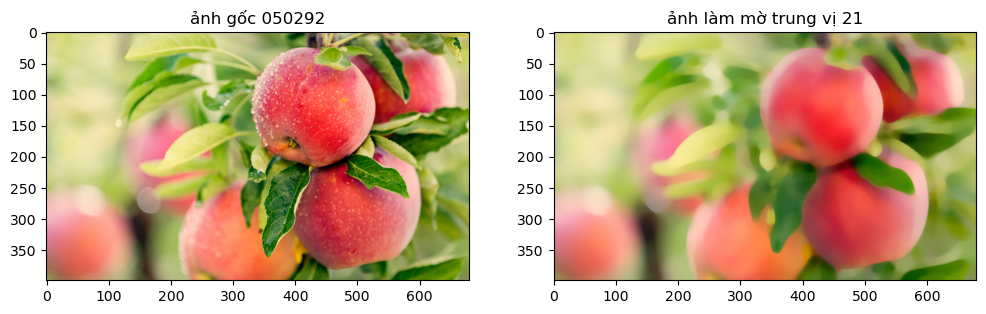

In [50]:
#Sử dụng bộ lọc trung vị trên ảnh:
img_median = cv2.medianBlur(img, 21)
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.imshow(img)
plt.title("ảnh gốc 050292")

plt.subplot(1,2,2)
plt.imshow(img_median)
plt.title("ảnh làm mờ trung vị 21")
plt.show()



In [51]:
#Giá trị điểm ảnh của ảnh gốc:
img[:,:,1]

array([[206, 207, 207, ..., 151, 169, 142],
       [205, 207, 208, ..., 146, 162, 144],
       [204, 207, 209, ..., 159, 174, 159],
       ...,
       [160, 158, 155, ..., 144, 144, 144],
       [167, 164, 161, ..., 144, 143, 143],
       [172, 169, 166, ..., 144, 143, 142]], shape=(399, 680), dtype=uint8)

In [52]:
#Giá trị điểm ảnh của ảnh sau khi sử dụng bộ lọc trung vị:
img_median[:,:,1]

array([[206, 207, 207, ..., 152, 152, 151],
       [206, 207, 207, ..., 156, 153, 152],
       [206, 207, 207, ..., 164, 164, 159],
       ...,
       [144, 141, 140, ..., 143, 143, 143],
       [149, 144, 143, ..., 143, 143, 143],
       [149, 149, 144, ..., 142, 142, 143]], shape=(399, 680), dtype=uint8)

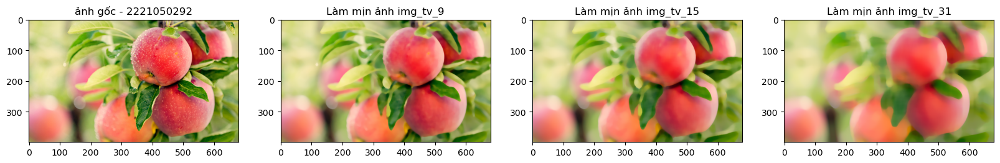

In [53]:
#Làm mờ ảnh theo phương pháp trung vị với kích thước bộ lọc khác nhau:
img_tv_10 = cv2.medianBlur(img,9) 
img_tv_15 = cv2.medianBlur(img,15) 
img_tv_31 = cv2.medianBlur(img,31) 
#Hiển thị kết quả 
#show images 
plt.figure(figsize= (20,8))

plt.subplot(1,4,1) 
plt.imshow(img)
plt.title("ảnh gốc - 2221050292")

plt.subplot(1,4,2) 
plt.imshow(img_tv_10)
plt.title("Làm mịn ảnh img_tv_9")

plt.subplot(1,4,3)
plt.imshow(img_tv_15)
plt.title("Làm mịn ảnh img_tv_15")

plt.subplot(1,4,4)
plt.imshow(img_tv_31)
plt.title("Làm mịn ảnh img_tv_31")
plt.show()

**3. phương thức lọc Gaussian cv2.GaussianBlur():**
Sử dụng Bộ lọc Gaussian (Gaussian Blur) là một bộ lọc làm trơn ảnh tuyến tính có trọng số, trong đó mỗi điểm ảnh đầu ra được tính bằng trung bình có trọng số của các điểm ảnh lân cận, với trọng số được xác định bởi hàm phân phối chuẩn (Gaussian distribution). 

**cv2.GaussianBlur(src, kernel,sigmaX, sigmaY, borderType)**

Ý nghĩa các tham số:

1. src: ảnh gốc cần thay đổi kích thước.
2. ksize =  (width, height): Kích thước cửa sổ trượt, phải là số dương và lẻ.
3. sigmaX: Độ lệch chuẩn theo trục X (Điều chỉnh độ mờ chính) 
4. sigmaY: Độ lệch chuẩn theo trục Y (thường để mặc định = sigmaX)
5. borderType: Phương pháp xử lý biên
   
Xem thêm thông tin về smoothing trong OpenCV: https://docs.opencv.org/3.4/dc/dd3/tutorial_gausian_median_blur_bilateral_filter.html

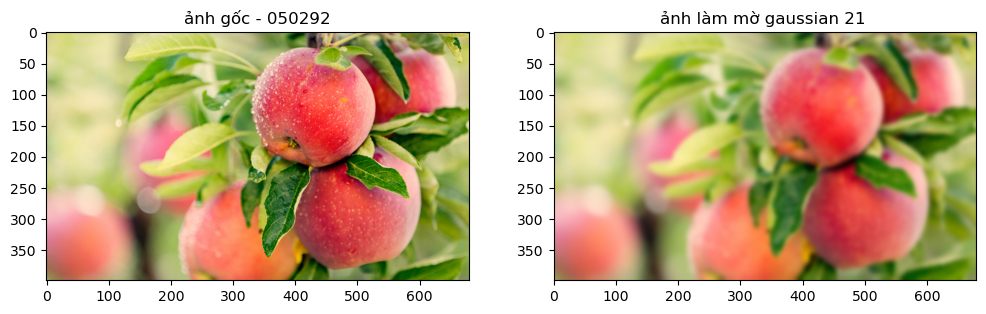

In [54]:
#Sử dụng bộ lọc Gaussian trên ảnh:
img_gauss = cv2.GaussianBlur(img,(21,21),0,0, cv2.BORDER_CONSTANT)

 
#show images 
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.imshow(img)
plt.title("ảnh gốc - 050292")

plt.subplot(1,2,2)
plt.imshow(img_gauss)
plt.title("ảnh làm mờ gaussian 21 ")
plt.show()



In [55]:
#Giá trị điểm ảnh của ảnh gốc:
img[:, : , 2] 


array([[130, 130, 128, ...,  68,  82,  60],
       [130, 130, 129, ...,  65,  74,  63],
       [129, 130, 132, ...,  72,  83,  70],
       ...,
       [102,  98,  95, ...,  88,  86,  86],
       [103, 100,  97, ...,  89,  88,  88],
       [105, 102,  99, ...,  91,  90,  87]], shape=(399, 680), dtype=uint8)

In [56]:
#Giá trị điểm ảnh của ảnh sau khi sử dụng bộ lọc Gaussian:

img_gauss[:, : , 2]


array([[131, 131, 130, ...,  76,  77,  77],
       [131, 131, 131, ...,  77,  77,  77],
       [131, 131, 131, ...,  79,  79,  79],
       ...,
       [ 90,  90,  89, ...,  85,  85,  85],
       [ 91,  91,  90, ...,  86,  86,  86],
       [ 91,  91,  90, ...,  86,  86,  86]], shape=(399, 680), dtype=uint8)

In [57]:
#Làm mờ ảnh theo phương pháp Gaussian với kích thước bộ lọc khác nhau:


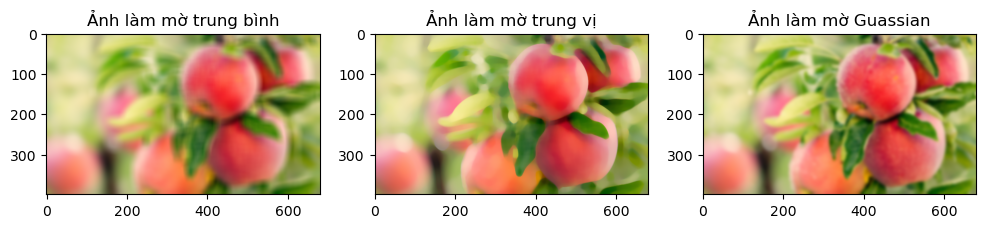

In [58]:
#So sánh các phương pháp làm mờ ảnh khác nhau: Trung bình - Trung vị - Gaussian:
plt.figure(figsize= (12,5))

plt.subplot(1,3,1) 
plt.imshow(img_blur)
plt.title("Ảnh làm mờ trung bình")

plt.subplot(1,3,2) 
plt.imshow(img_median)
plt.title("Ảnh làm mờ trung vị")

plt.subplot(1,3,3)
plt.imshow(img_gauss)
plt.title("Ảnh làm mờ Guassian")

plt.show()



## THỰC HÀNH 2.8: 
---
**Yêu cầu 1:** Sinh viên đọc ảnh images/Thuchanh2_8.jpeg, dạng xám và hiển thị ảnh

**Yêu cầu 2:** Sử dụng phương pháp làm mịn trung bình với kernel 5x5, 10x10, 20x30 và hiển thị kết quả

**Yêu cầu 3:** Sử dụng phương pháp làm mịn trung vị với k =  7, 11, 21 và hiển thị kết quả

**Yêu cầu 4:** Sử dụng phương pháp làm mịn Gaussian với kernel = (7,7) và sigmaY, sigmaY lần lượt là (0,0); (0,20); (20,0) và hiển thị kết quả

<img src='images/Thuchanh2_8.jpeg' width='400px'>

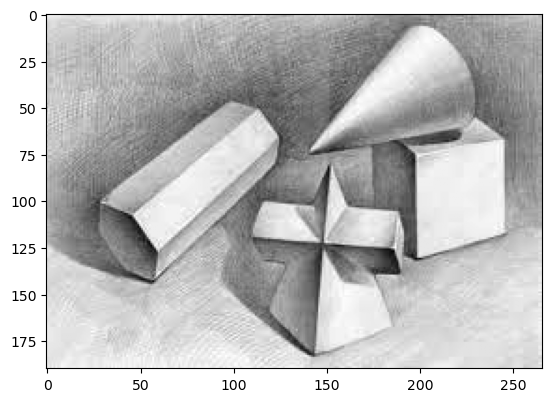

In [59]:
#{SINH VIÊN VIẾT CODE VÀO ĐÂY}
img_gra = cv2.imread('images/Thuchanh2_8.jpeg') 
img_gray = cv2.cvtColor(img_gra, cv2.COLOR_BGR2GRAY)

#đọc ảnh xám 
plt.imshow(img_gray,cmap = 'gray')
plt.show()

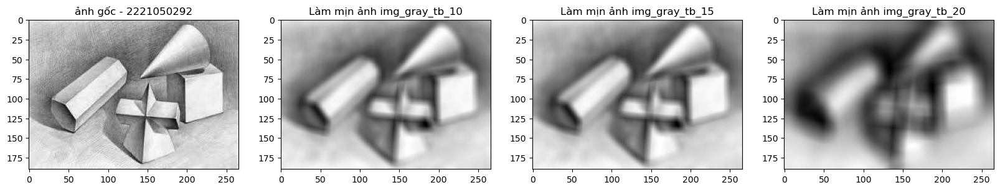

In [60]:
#Làm mịn ảnh với các kernel khác nhau:
img_gray_tb_10 = cv2.blur(img_gray,(10,10)) 
img_gray_tb_15 = cv2.blur(img_gray,(10,10)) 
img_gray_tb_20 = cv2.blur(img_gray,(20,30))
#Hiển thị kết quả 
#show images 
plt.figure(figsize= (20,8))

plt.subplot(1,4,1) 
plt.imshow(img_gray,cmap = 'gray')
plt.title("ảnh gốc - 2221050292")

plt.subplot(1,4,2) 
plt.imshow(img_gray_tb_10,cmap = 'gray')
plt.title("Làm mịn ảnh img_gray_tb_10")

plt.subplot(1,4,3)
plt.imshow(img_gray_tb_15,cmap = 'gray')
plt.title("Làm mịn ảnh img_gray_tb_15")

plt.subplot(1,4,4)
plt.imshow(img_gray_tb_20,cmap = 'gray')
plt.title("Làm mịn ảnh img_gray_tb_20")
plt.show()

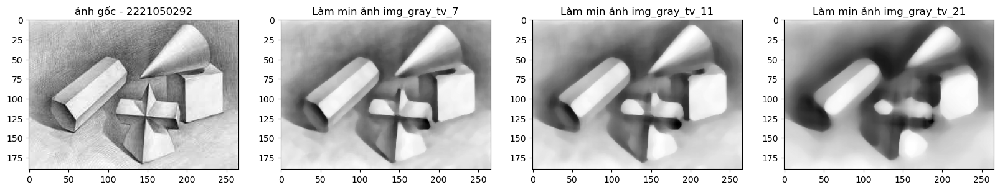

In [61]:
#Làm mịn ảnh với các kernel khác nhau sử dụng bộ lọc trung vị:
img_gray_tv_7 = cv2.medianBlur(img_gray,7) 
img_gray_tv_11 = cv2.medianBlur(img_gray,11) 
img_gray_tv_21 = cv2.medianBlur(img_gray,21) 
#Hiển thị kết quả 
#show images 
plt.figure(figsize= (20,8))

plt.subplot(1,4,1) 
plt.imshow(img_gray,cmap = 'gray')
plt.title("ảnh gốc - 2221050292")

plt.subplot(1,4,2) 
plt.imshow(img_gray_tv_7,cmap = 'gray')
plt.title("Làm mịn ảnh img_gray_tv_7")

plt.subplot(1,4,3)
plt.imshow(img_gray_tv_11,cmap = 'gray')
plt.title("Làm mịn ảnh img_gray_tv_11")

plt.subplot(1,4,4)
plt.imshow(img_gray_tv_21,cmap = 'gray')
plt.title("Làm mịn ảnh img_gray_tv_21")
plt.show()

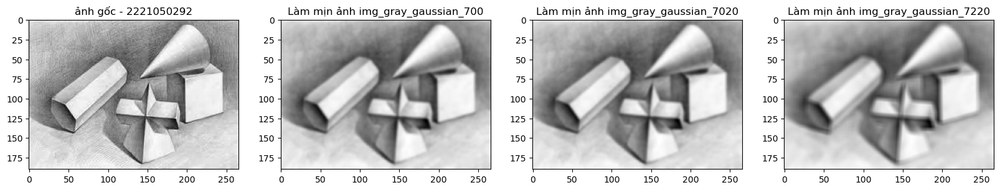

In [62]:
#Làm mịn ảnh với các kernel khác nhau sử dụng bộ lọc Gaussian:
img_gray_gaussian_700 = cv2.GaussianBlur(img_gray,(7,7),0,0) 
img_gray_gaussian_7020 = cv2.GaussianBlur(img_gray,(7,7),0,20) 
img_gray_gaussian_7220 = cv2.GaussianBlur(img_gray,(7,7),20,0) 
#Hiển thị kết quả 
#show images 
plt.figure(figsize= (20,8))

plt.subplot(1,4,1) 
plt.imshow(img_gray,cmap = 'gray')
plt.title("ảnh gốc - 2221050292")

plt.subplot(1,4,2) 
plt.imshow(img_gray_gaussian_700,cmap = 'gray')
plt.title("Làm mịn ảnh img_gray_gaussian_700")

plt.subplot(1,4,3)
plt.imshow(img_gray_gaussian_7020,cmap = 'gray')
plt.title("Làm mịn ảnh img_gray_gaussian_7020")

plt.subplot(1,4,4)
plt.imshow(img_gray_gaussian_7220,cmap = 'gray')
plt.title("Làm mịn ảnh img_gray_gaussian_7220")
plt.show()

## 2. Nhiễu và khử nhiễu trong ảnh
---
Nhiễu (Noise) là các tín hiệu không mong muốn xuất hiện trong ảnh, làm biến đổi giá trị cường độ sáng hoặc màu sắc của các điểm ảnh, khiến ảnh bị mờ, kém rõ nét hoặc mất chi tiết quan trọng.


Nhiễu thường phát sinh trong quá trình:
* Cảm biến máy ảnh thu nhận tín hiệu (sensor noise)
* Truyền dẫn dữ liệu (channel noise)
* Ánh sáng môi trường (low-light conditions)
* Xử lý và nén ảnh (compression artifacts)

Ảnh nhiễu được biểu diễn bằng biểu thức:

g(x,y) = f(x,y) + ⍺(x,y)

Trong đó:

* f(x,y): Ảnh gốc
* ⍺(x,y): Nhiễu
* g(x,y): Ảnh sau khi bị nhiễu tác động.


## Một số loại nhiễu cơ bản
---
1. Nhiễu Gaussian
2. Nhiễu muối tiêu
3. Nhiều Speckle

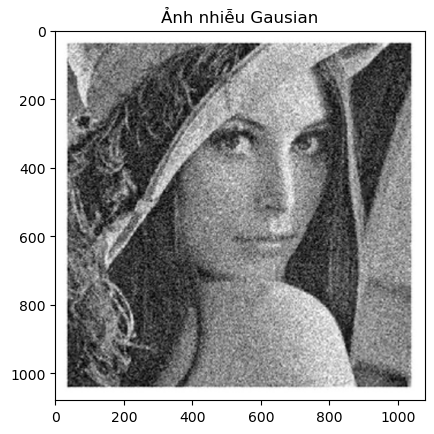

In [63]:
#Ví dụ các loại nhiễu:
img_noise_gau = cv2.imread('images/pic_noise_gaussian.jpg', 0)
#Hiển thị ảnh:
plt.imshow(img_noise_gau, cmap='gray')
plt.title('Ảnh nhiễu Gausian')
plt.show()

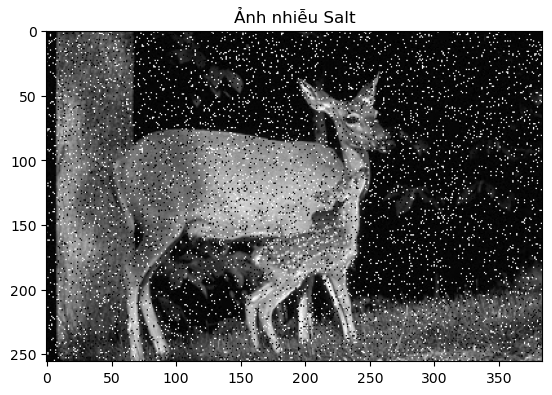

In [64]:
img_noise_tieu = cv2.imread('images/pic_noise_salt.jpg', 0)
#Hiển thị ảnh:
plt.imshow(img_noise_tieu, cmap='gray')
plt.title('Ảnh nhiễu Salt')
plt.show()

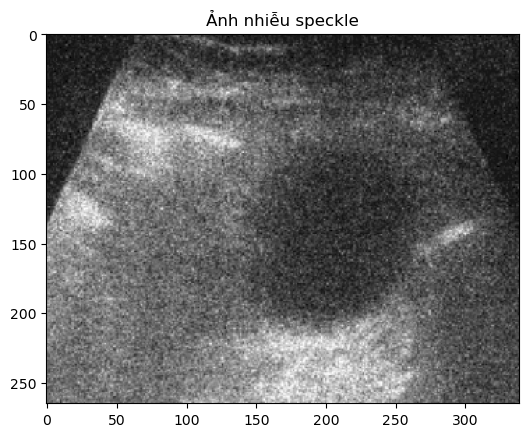

In [65]:
img_noise_speckle = cv2.imread('images/pic_noise_speckle.png', 0)
#Hiển thị ảnh:
plt.imshow(img_noise_speckle, cmap='gray')
plt.title('Ảnh nhiễu speckle')
plt.show()

## Khử nhiễu trong ảnh:
---
Khử nhiễu là quá trình làm giảm hoặc loại bỏ nhiễu khỏi ảnh, trong khi bảo toàn tối đa chi tiết và cấu trúc quan trọng (đặc biệt là các biên và đường nét).

Mục đích: là để thu nhận được ảnh càng gần với ảnh gốc càng tốt

Một số phương pháp loại bỏ nhiễu:
* Bộ Lọc làm trung bình: Trung bình số học, hình học, Harmonic, Contra harmonic
* Bộ Lọc thứ tự thống kê: Trung vị, Max, Min, trung bình cắt alpha.
* Bộ Lọc thích nghi

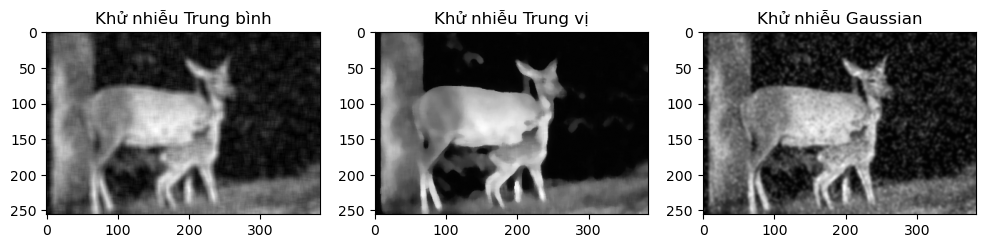

In [66]:
# Sử dụng 3 phương pháp làm mờ ảnh: Trung bình, trung vị, Gaussian
img_noise_mean = cv2.blur(img_noise_tieu, (9, 9))
img_noise_median = cv2.medianBlur(img_noise_tieu, 9)
img_noise_gauss = cv2.GaussianBlur(img_noise_tieu, (9, 9), 0)

# Hiển thị kết quả:
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_noise_mean, cmap='gray')
plt.title('Khử nhiễu Trung bình')

plt.subplot(1, 3, 2)
plt.imshow(img_noise_median, cmap='gray')
plt.title('Khử nhiễu Trung vị')

plt.subplot(1, 3, 3)
plt.imshow(img_noise_gauss, cmap='gray')
plt.title('Khử nhiễu Gaussian')

plt.show()

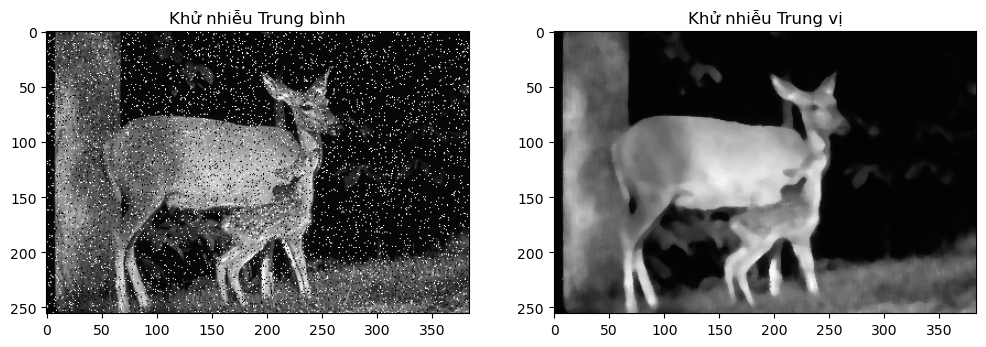

In [67]:
#Trung vị khử được các chấm đen trắng -->mờ ---> tùy chỉnh ksize
img_noise_ok = cv2.medianBlur(img_noise_tieu, 7)

# So sánh ảnh gốc - ảnh khử nhiễu:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_noise_tieu, cmap='gray')
plt.title('Khử nhiễu Trung bình')

plt.subplot(1, 2, 2)
plt.imshow(img_noise_ok, cmap='gray')
plt.title('Khử nhiễu Trung vị')

plt.show()

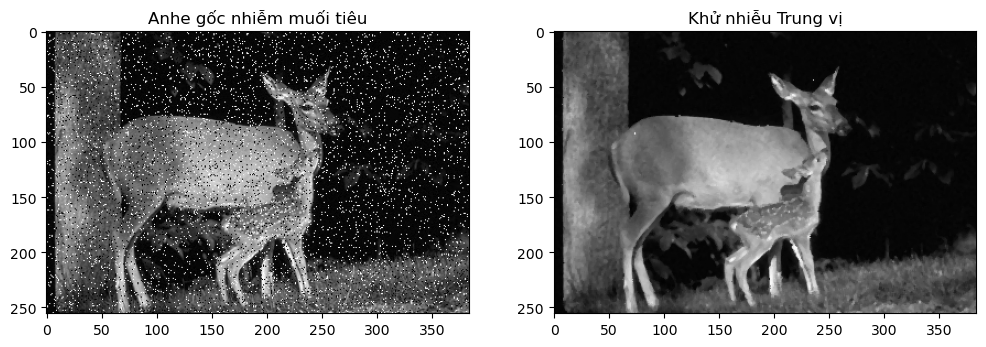

In [68]:
img_noise_ok = cv2.medianBlur(img_noise_tieu, 3)

# So sánh ảnh gốc - ảnh khử nhiễu:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_noise_tieu, cmap='gray')
plt.title('Anhe gốc nhiễm muối tiêu')

plt.subplot(1, 2, 2)
plt.imshow(img_noise_ok, cmap='gray')
plt.title('Khử nhiễu Trung vị')

plt.show()

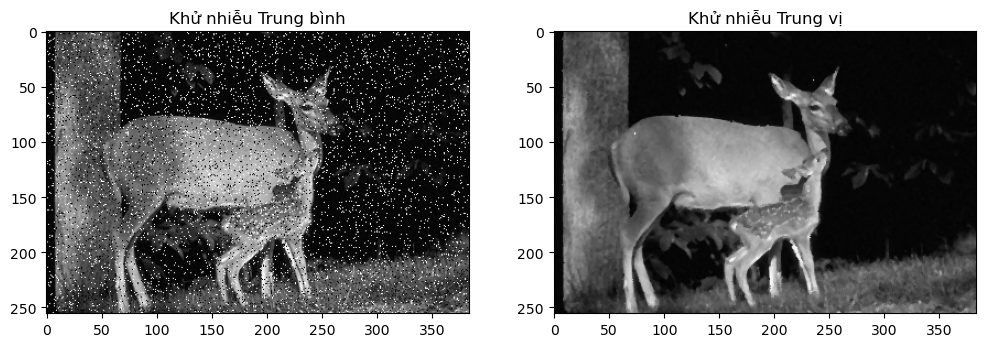

In [69]:
# Trung vị khử được các chấm đen trắng --> Muối -- Tùy chỉnh ksize
img_noise_OK = cv2.medianBlur(img_noise_tieu, 3)

# So sánh ảnh gốc – ảnh khử nhiễu:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(img_noise_tieu, cmap='gray')
plt.title('Khử nhiễu Trung bình')

plt.subplot(1,2,2)
plt.imshow(img_noise_OK, cmap='gray')
plt.title('Khử nhiễu Trung vị')

plt.show()

## THỰC HÀNH 2.9: 
---
**Yêu cầu 1:** Sinh viên đọc ảnh images/Thuchanh2_9_1.jpeg. Lựa chọn phương pháp khử nhiễu và các tham số phù hợp để thu được ảnh khử nhiễu tốt nhất. Lưu ảnh đã xử lý vào thư mục images/Saves/MSV_brain.png

<img src='images/Thuchanh2_9_1.jpeg' width='200px'>

**Yêu cầu 2:** Sinh viên đọc ảnh images/Thuchanh2_9_2.png và hiển thị ảnh. Lựa chọn phương pháp khử nhiễu và các tham số phù hợp để thu được ảnh khử nhiễu tốt nhất. Lưu ảnh đã xử lý vào thư mục images/Saves/MSV_plane.png

<img src='images/Thuchanh2_9_2.png' width='200px'>

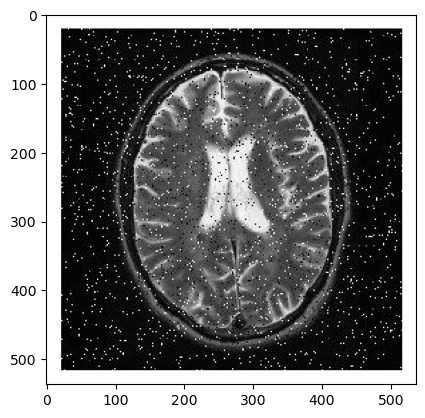

In [70]:
#{SINH VIÊN VIẾT CODE VÀO ĐÂY}
img_yc1 = cv2.imread('images/Thuchanh2_9_1.jpeg.')

#hiển thị ảnh 
plt.imshow(img_yc1, cmap = 'gray')
plt.show()

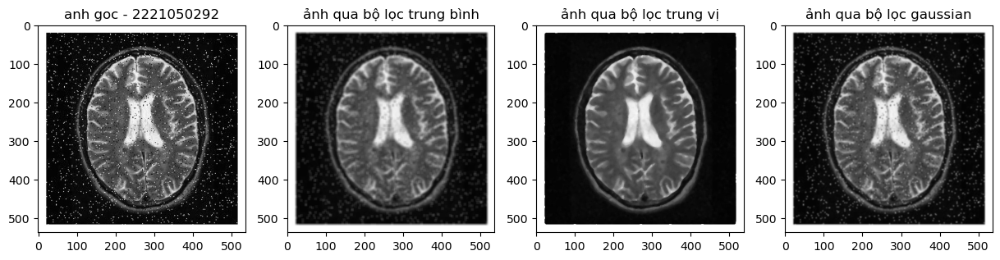

In [71]:
#áp dụng bộ lọc trung bình để khử nhiễu : 
img_yc1_ok_tb = cv2.blur(img_yc1,(7,7))

#áp dụng bộ lọc trung vị để khử nhiễu : 
img_yc1_ok_tv = cv2.medianBlur(img_yc1,7)

#áp dụng bộ lọc gaussian để khử nhiễu : 
img_yc1_ok_gaussian = cv2.GaussianBlur(img_yc1,(7,7),0,0) 

#hiển thị kết quả 
plt.figure(figsize = (15,5))

plt.subplot(1,4,1)
plt.imshow(img_yc1,cmap='gray')
plt.title('anh goc - 2221050292') 

plt.subplot(1,4,2)
plt.imshow(img_yc1_ok_tb,cmap='gray')
plt.title('ảnh qua bộ lọc trung bình') 

plt.subplot(1,4,3)
plt.imshow(img_yc1_ok_tv,cmap='gray')
plt.title('ảnh qua bộ lọc trung vị') 

plt.subplot(1,4,4)
plt.imshow(img_yc1_ok_gaussian,cmap='gray')
plt.title('ảnh qua bộ lọc gaussian') 

plt.show()

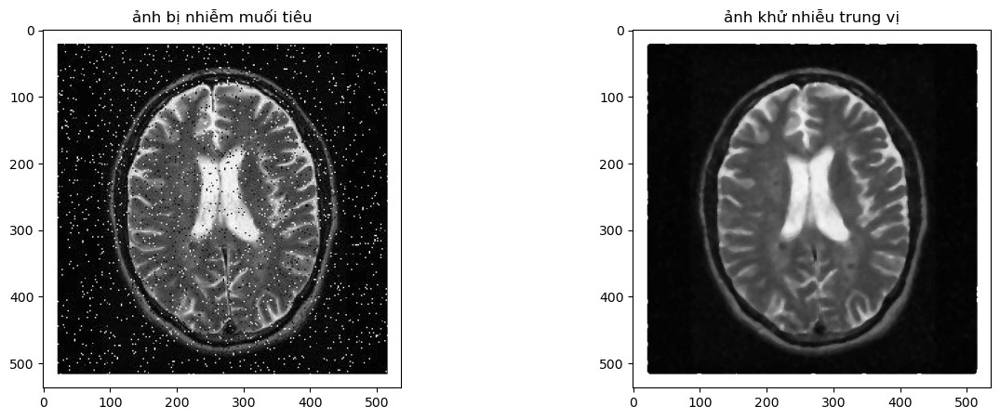

True

In [72]:
#hiển ảnh trước và sau khi khử nhiễu : 
#hiển thị kết quả 
plt.figure(figsize = (15,5))

plt.subplot(1,2,1)
plt.imshow(img_yc1,cmap='gray')
plt.title('ảnh bị nhiễm muối tiêu') 

plt.subplot(1,2,2)
plt.imshow(img_yc1_ok_tv,cmap='gray')
plt.title('ảnh khử nhiễu trung vị') 
plt.show()
# Lưu ảnh đã xử lý
cv2.imwrite('images/Saves/2221050292_brain.png', img_yc1_ok_tv)

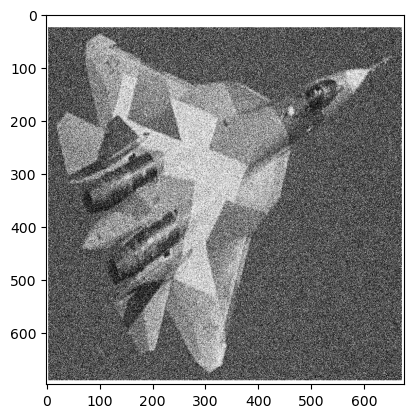

In [73]:
#đọc ảnh 
img_yc2 = cv2.imread('images/Thuchanh2_9_2.png')

#hiển thị ảnh 
plt.imshow(img_yc2, cmap = 'gray')
plt.show()

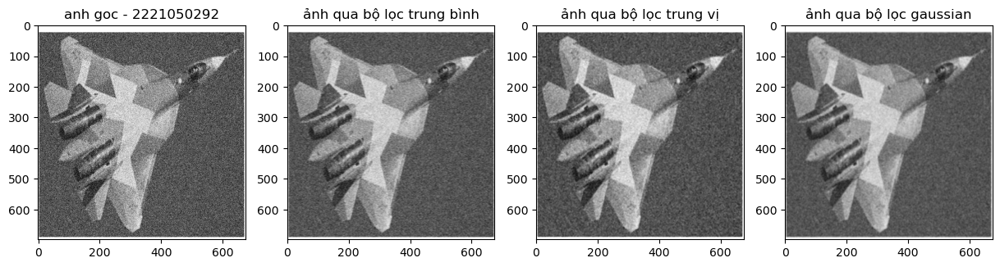

In [99]:
#{SINH VIÊN VIẾT CODE VÀO ĐÂY}
#áp dụng bộ lọc trung bình để khử nhiễu : 
img_yc2_ok_tb = cv2.blur(img_yc2,(5,3))

#áp dụng bộ lọc trung vị để khử nhiễu : 
img_yc2_ok_tv = cv2.medianBlur(img_yc2,5)

#áp dụng bộ lọc gaussian để khử nhiễu : 
img_yc2_ok_gaussian = cv2.GaussianBlur(img_yc2,(9,9),0,0) 

#hiển thị kết quả 
plt.figure(figsize = (15,5))

plt.subplot(1,4,1)
plt.imshow(img_yc2,cmap='gray')
plt.title('anh goc - 2221050292') 

plt.subplot(1,4,2)
plt.imshow(img_yc2_ok_tb,cmap='gray')
plt.title('ảnh qua bộ lọc trung bình') 

plt.subplot(1,4,3)
plt.imshow(img_yc2_ok_tv,cmap='gray')
plt.title('ảnh qua bộ lọc trung vị') 

plt.subplot(1,4,4)
plt.imshow(img_yc2_ok_gaussian,cmap='gray')
plt.title('ảnh qua bộ lọc gaussian') 

plt.show()


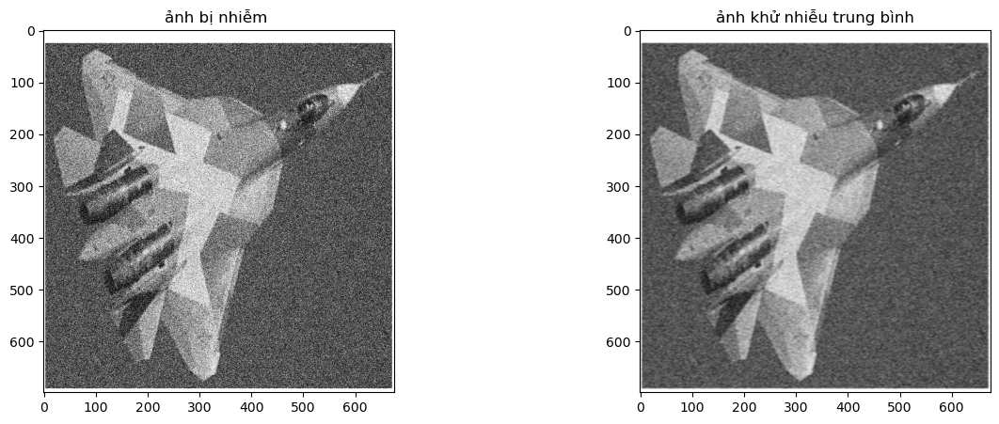

True

In [75]:

#hiển ảnh trước và sau khi khử nhiễu : 
#hiển thị kết quả 
plt.figure(figsize = (15,5))

plt.subplot(1,2,1)
plt.imshow(img_yc2,cmap='gray')
plt.title('ảnh bị nhiễm ') 

plt.subplot(1,2,2)
plt.imshow(img_yc2_ok_tb,cmap='gray')
plt.title('ảnh khử nhiễu trung bình') 
plt.show()

# Lưu ảnh đã xử lý
cv2.imwrite('images/Saves/2221050292_plane.png', img_yc2_ok_tb)

## 3. Nhân tích chập - Lọc ảnh 2D (Convolution)
---
Nguyên tắc chung của các phương pháp lọc là cho ma trận ảnh nhân với một ma trận lọc (Kernel). Ma trận lọc lọc (Kernel) còn có thể được gọi là cửa sổ chập (trong phép nhân chập), cửa sổ lọc, mặt nạ,…Việc nhân ảnh với ma trận lọc giống như việc trượt ma trận lọc theo hàng trên ảnh và nhân với từng vùng của ảnh, cộng các kết quả lại tạo thành kết quả của điểm ảnh trung tâm.

Với mỗi phép lọc ta có những ma trận lọc (Kernel) khác nhau, không có một quy định cụ thể nào cho việc xác định M. Kích thước ma trận M là một số lẻ. Ví dụ: 3x3, 5x5.

OpenCV hỗ trợ phương thức lọc ảnh 2D:
 **cv2.filter2D(img,ddepth, kernel)**
 
 Trong đó:
1. img: ảnh gốc muốn áp dụng bộ lọc
2. ddepth: Độ sâu của ảnh đầu ra; -1: độ sâu của ảnh đầu ra bằng độ sâu của ảnh đầu vào.
3. kernel: ma trận lọc

https://www.geeksforgeeks.org/python-opencv-filter2d-function/

https://setosa.io/ev/image-kernels/

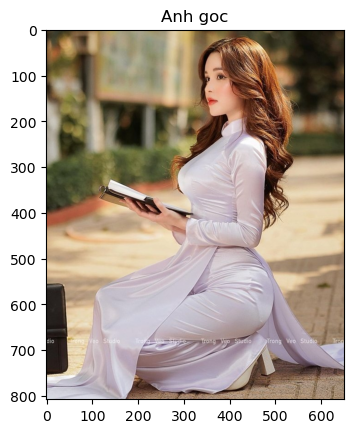

In [76]:
#Đọc ảnh mẫu Pic_1.jpg
img= cv2.imread('images/Pic_1.jpg', cv2.IMREAD_COLOR_RGB)
plt.imshow(img)
plt.title('Anh goc')
plt.show()


## Một số bộ lọc thông dụng:
---
### 1. Bộ lọc identity:

In [77]:
#Khởi tạo kernel:
kernel_identity = np.array([[0,0,0],
                            [0,8,0],
                            [0,0,0]])
print('Kernel indentity:\n', kernel_identity)



Kernel indentity:
 [[0 0 0]
 [0 8 0]
 [0 0 0]]


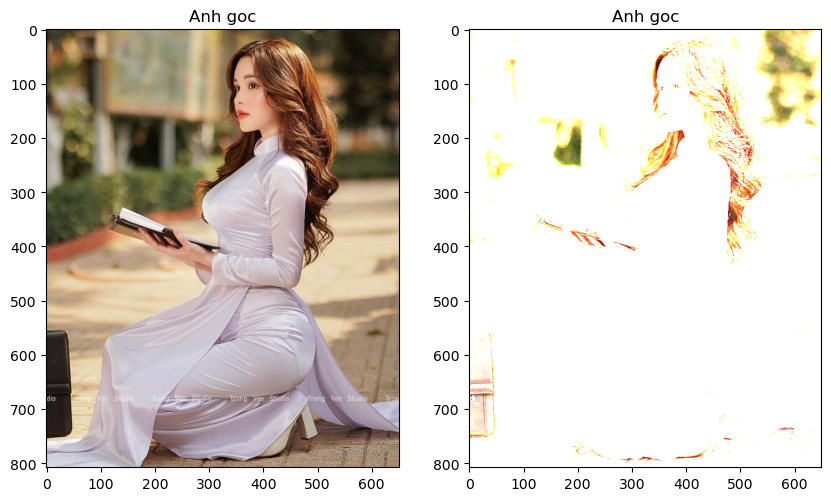

In [78]:
#Thực hiện lọc ảnh với kernel ở trên:
img_identity = cv2.filter2D(img, -1, kernel_identity)

plt.figure(figsize=(10,7))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Anh goc')

plt.subplot(1,2,2)
plt.imshow(img_identity)
plt.title('Anh goc')
plt.show()

### 2. Bộ lọc phát hiện góc của ảnh (Edge detection))

In [79]:
#Khởi tạo kernel:
kernel_edge = np.array([[-1,-1,-1],
                            [-1,8,-1],
                            [-1,-1,-1]])
print('kernel_edge:\n', kernel_edge)



kernel_edge:
 [[-1 -1 -1]
 [-1  8 -1]
 [-1 -1 -1]]


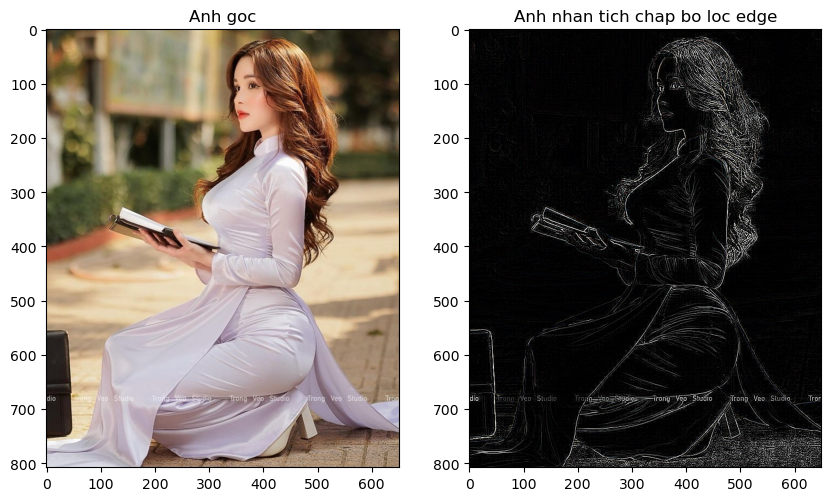

In [80]:
#Thực hiện lọc ảnh với kernel ở trên:
img_edge = cv2.filter2D(img, -1, kernel_edge)

plt.figure(figsize=(10,7))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Anh goc')

plt.subplot(1,2,2)
plt.imshow(img_edge)
plt.title('Anh nhan tich chap bo loc edge')
plt.show()



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-790.0..1019.0].


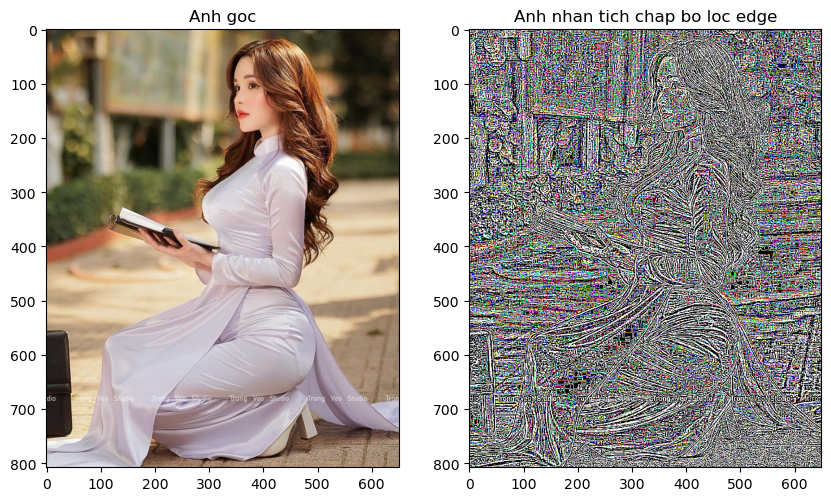

In [81]:
img_edge = cv2.filter2D(img, cv2.CV_32F, kernel_edge)

plt.figure(figsize=(10,7))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Anh goc')

plt.subplot(1,2,2)
plt.imshow(img_edge)
plt.title('Anh nhan tich chap bo loc edge')
plt.show()


### 3. Bộ lọc sắc nét Sharpen kernel:

In [82]:
#Khởi tạo kernel:
kernel_sharpen = np.array([[0,-1,0],
                            [-1,5,-1],
                            [0,-1,0]])
print('kernel_sharpen:\n', kernel_sharpen)




kernel_sharpen:
 [[ 0 -1  0]
 [-1  5 -1]
 [ 0 -1  0]]


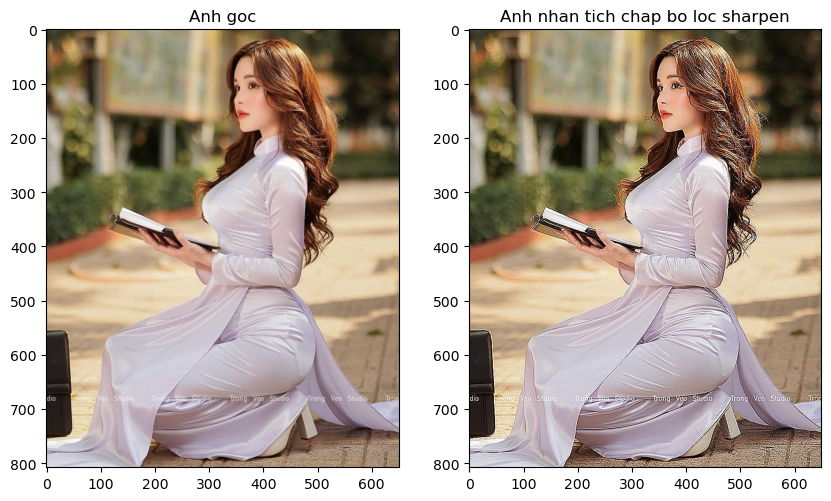

In [83]:
#Thực hiện lọc ảnh với kernel ở trên:
img_sharpen = cv2.filter2D(img, -1, kernel_sharpen)

plt.figure(figsize=(10,7))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Anh goc')

plt.subplot(1,2,2)
plt.imshow(img_sharpen)
plt.title('Anh nhan tich chap bo loc sharpen')
plt.show()


### 4. Bộ lọc emboss kernel:


In [84]:
#Khởi tạo kernel:
kernel_emboss = np.array([[-2,-1,0],
                            [-1,1,1],
                            [0,1,2]])
print('kernel_emboss:\n',kernel_emboss)






kernel_emboss:
 [[-2 -1  0]
 [-1  1  1]
 [ 0  1  2]]


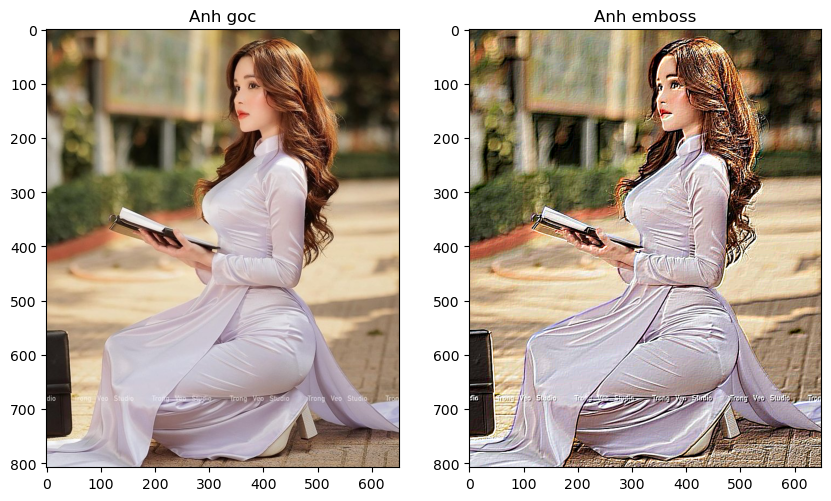

In [93]:
#Thực hiện lọc ảnh với kernel ở trên:
img_emboss = cv2.filter2D(img, -1, kernel_emboss)

plt.figure(figsize=(10,7))
plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Anh goc')

plt.subplot(1,2,2)
plt.imshow(img_emboss)
plt.title('Anh emboss')
plt.show()




## THỰC HÀNH 2.10: 
---
Yêu cầu :
* Sinh viên đọc và hiển thị ảnh images/Thuchanh2_10. ở chế độ mặc định.
* Áp dụng 4 bộ lọc khác nhau trên ảnh và hiển thị kết quả (xem chi tiết các bộ lọc trong slide bài giảng)
<img src = 'images/Thuchanh2_10.png' width='300px'>

https://setosa.io/ev/image-kernels/

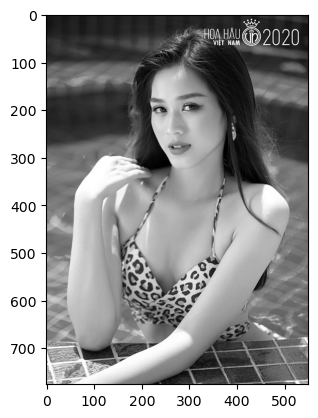

In [88]:
#{SINH VIÊN VIẾT CODE VÀO ĐÂY}
img_thuchanh = cv2.imread('images/Thuchanh2_10.png')
plt.imshow(img_thuchanh)
plt.show()

In [97]:
#Thực hiện lọc ảnh với bộ lọc identity
img_identity_thuchanh = cv2.filter2D(img_thuchanh, -1 , kernel_identity) 
#Thực hiện lọc ảnh với bộ lọc phát hiện cạnh Edge detection : 
img_identity_edge_thuchanh = cv2.filter2D(img_thuchanh, -1 , kernel_edge) 
#Thực hiện lọc ảnh với Bộ lọc sắc nét Sharpen kernel:
img_identity_harpen_thuchanh = cv2.filter2D(img_thuchanh, -1 , kernel_sharpen) 
img_identity_emboss_thuchanh = cv2.filter2D(img_thuchanh, -1 , kernel_emboss) 

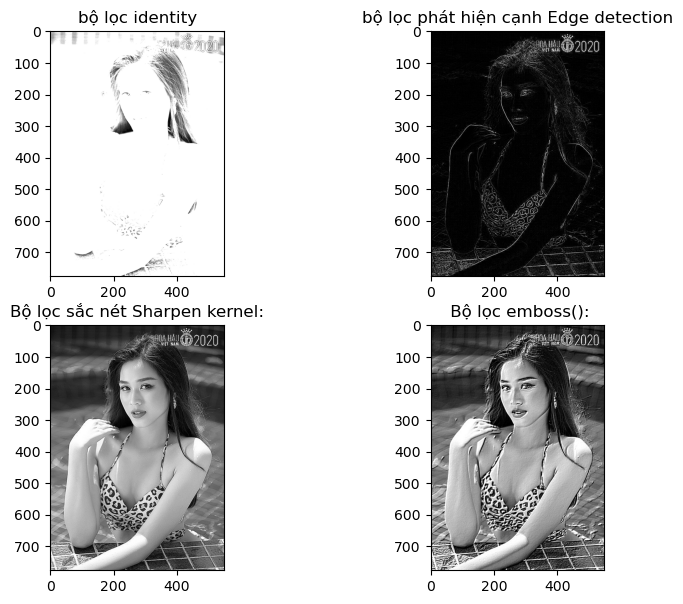

In [98]:
#hiển thị 4 bộ lọc 
plt.figure(figsize = (9,7))
plt.subplot(2,2,1)
plt.imshow(img_identity_thuchanh)
plt.title('bộ lọc identity')

plt.subplot(2,2,2)
plt.imshow(img_identity_edge_thuchanh)
plt.title('bộ lọc phát hiện cạnh Edge detection')

plt.subplot(2,2,3)
plt.imshow(img_identity_harpen_thuchanh)
plt.title('Bộ lọc sắc nét Sharpen kernel:')

plt.subplot(2,2,4)
plt.imshow(img_identity_emboss_thuchanh)
plt.title(' Bộ lọc emboss():')

plt.show()